
## 1. Load and Split the Dataset

Load the original dataset and separate the features from the target.

Split the data into training (80%) and testing (20%) sets.

We use stratification to preserve the target-class proportions.


In [37]:
import pandas as pd 
import numpy as np 

from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/raw/student_mental_health.csv")

X = df.drop(columns=["Student_ID","Mental_Health_Risk"])
y= df["Mental_Health_Risk"]

X_train , X_test , y_train , y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (1600, 15)
Testing shape: (400, 15)



## 2. Identify Feature Types

Separate numerical and categorical features.

Numerical features will be imputed and scaled, while categorical features will be imputed and encoded.


In [38]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "str", "category"]).columns.tolist()


print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)
print("\nNumber of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

Numerical features: ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']

Categorical features: ['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']

Number of numerical features: 10
Number of categorical features: 5



## 3. Build the Preprocessing Pipeline

Create separate transformers for numerical and categorical features.

- Numerical: fill missing values with the median, then scale.
- Categorical: fill missing values with the most frequent value, then apply One-Hot Encoding.

Use ColumnTransformer to combine both transformations.


In [39]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler , OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])



## 4. Define the Classification Models

Create three models: Logistic Regression, KNN and Random Forest.

Combine each model with the preprocessing Pipeline so all models receive the same preprocessing steps.



In [40]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

knn_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier())
])

rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(random_state=42))
])




### 5. Organize Models

We will compare three classification models using the same training data and preprocessing steps.

In [41]:
models = {
    "Logistic Regression": model_pipeline,
    "KNN": knn_pipeline,
    "Random Forest": rf_pipeline
}

### Hyperparameter Tuning
We use GridSearchCV to optimize Logistic Regression, KNN, and Random Forest. Each model is evaluated using 5-fold Stratified Cross-Validation, and the best configuration is selected based on macro F1-score.

### Cross-Validation Strategy
We use StratifiedKFold with 5 folds to preserve the proportions of the three target classes during cross-validation.

In [42]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


In [43]:
params_grids={
    "Logistic Regression": {
        "classifier__C": [0.1, 1 , 10]
    },

    "KNN": {
        "classifier__n_neighbors": [3, 5, 7, 9],
        "classifier__weights": ["uniform", "distance"]
    },

    "Random Forest": {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [None, 10, 20]
    }
}

### Model Optimization
We run GridSearchCV on each model pipeline and compare their best cross-validation F1-scores.

In [44]:
from sklearn.model_selection import GridSearchCV

grid_results = {}

for name, pipeline in models.items():

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=params_grids[name],
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1
    )

    grid_search.fit(X_train,y_train)

    grid_results[name] = grid_search

### Best Model Comparison
We compare the best cross-validation F1-scores of the three optimized models to identify the most promising model.

In [46]:
comparison = pd.DataFrame({
    name: {
        "Best CV F1-score": search.best_score_,
        "Best Parameters": search.best_params_
    }
    for name, search in grid_results.items()
}).T

comparison

,Best CV F1-score,Best Parameters
Logistic Regression,0.750073,{'classifier__C': 10}
KNN,0.617264,"{'classifier__n_neighbors': 9, 'classifier__we..."
Random Forest,0.677658,"{'classifier__max_depth': 10, 'classifier__n_e..."


### Best Model Selection
We select the Logistic Regression model with the best hyperparameters found by GridSearchCV for final evaluation.

In [47]:
best_search = grid_results["Logistic Regression"]

best_pipeline = best_search.best_estimator_

print("Best parameters:", best_search.best_params_)
print("Best CV F1-score:", best_search.best_score_)

Best parameters: {'classifier__C': 10}
Best CV F1-score: 0.7500729022933624


### Final Model Evaluation
We evaluate the selected model on the independent test set to measure its ability to predict unseen student data.

In [48]:
y_pred = best_pipeline.predict(X_test)

print("Predictions:", y_pred[:10])
print("Actual values:", y_test[:10].values)


Predictions: ['High' 'Medium' 'Medium' 'High' 'High' 'Low' 'High' 'High' 'Low' 'Medium']
Actual values: <StringArray>
['High', 'Medium', 'Low', 'Medium', 'High', 'Low', 'High', 'High', 'Low',
 'High']
Length: 10, dtype: str


### Classification Metrics
We evaluate the selected model using Accuracy, Precision, Recall, and F1-score on unseen test data.

In [50]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Accuarcy: ", accuracy_score(y_test, y_pred))
print("Precision: ", precision_score(y_test, y_pred, average="macro"))
print("Recall: ", recall_score(y_test, y_pred, average="macro"))
print("F1 Score: ", f1_score(y_test, y_pred , average="macro"))

Accuarcy:  0.7525
Precision:  0.7519222323570149
Recall:  0.7517825311942959
F1 Score:  0.751822144102191


### Confusion Matrix
We visualize the model's predictions against the actual classes to understand which categories are correctly classified and which are confused.

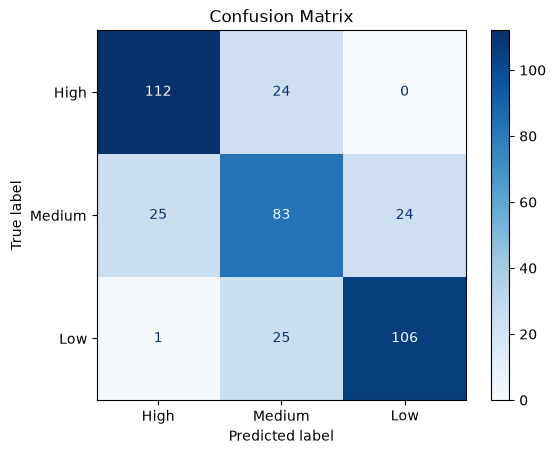

In [51]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["High", "Medium", "Low"],
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.show()

### Classification Report
We examine Precision, Recall, and F1-score separately for each target class.

In [52]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

        High       0.81      0.82      0.82       136
         Low       0.82      0.80      0.81       132
      Medium       0.63      0.63      0.63       132

    accuracy                           0.75       400
   macro avg       0.75      0.75      0.75       400
weighted avg       0.75      0.75      0.75       400



### Save the Best Model
We save the complete pipeline, including preprocessing and the trained classifier, so it can be reused without repeating training.

In [54]:
import joblib
from pathlib import Path

models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

model_path = models_dir / "mindscope_model.joblib"

joblib.dump(best_pipeline, model_path)

print("Moodel saved successsfuly !!")



Moodel saved successsfuly !!


### Load and Verify the Saved Model
We reload the saved pipeline and use it to predict new samples to verify that it works correctly.

In [55]:
loaded_model = joblib.load(model_path)

test_predictions = loaded_model.predict(X_test)

print("First 10 predictions:", test_predictions[:10])
print("Model loaded and predictions generated successfully!")

First 10 predictions: ['High' 'Medium' 'Medium' 'High' 'High' 'Low' 'High' 'High' 'Low' 'Medium']
Model loaded and predictions generated successfully!
